In [11]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

Python: 3.13.16
qiskit 2.2.3
qiskit-algorithms 0.4.0
qiskit-nature 0.7.2
pyscf 2.10.0
numpy 2.1.3
scipy 1.16.3
scikit-learn 1.6.1
설치 완료: 다음 실행 코드 셀로 이동합니다.


Running QAOA Logistics Optimization...

QAOA Logistics Results & Verification
관측된 유효 후보 중 최소 비용 경로: 0 → 3 → 2 → 1 → 0
선택 경로 비용      : 18.0 / 전수 탐색 최소 비용: 18.0
해당 경로 관측 확률 : 0.2007
평균 비용(벌점 포함): 21.522461
최적해 관측 확률    : 0.478
검증 통과: QAOA가 최적의 물류 경로를 정확히 찾아냈습니다.


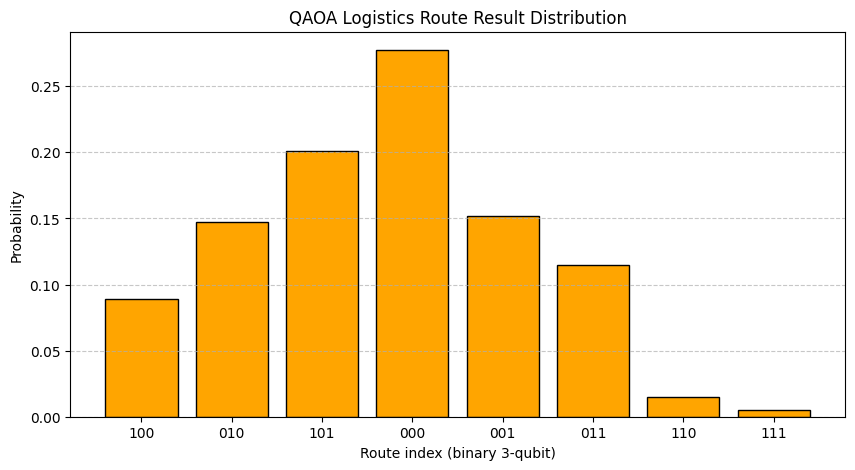

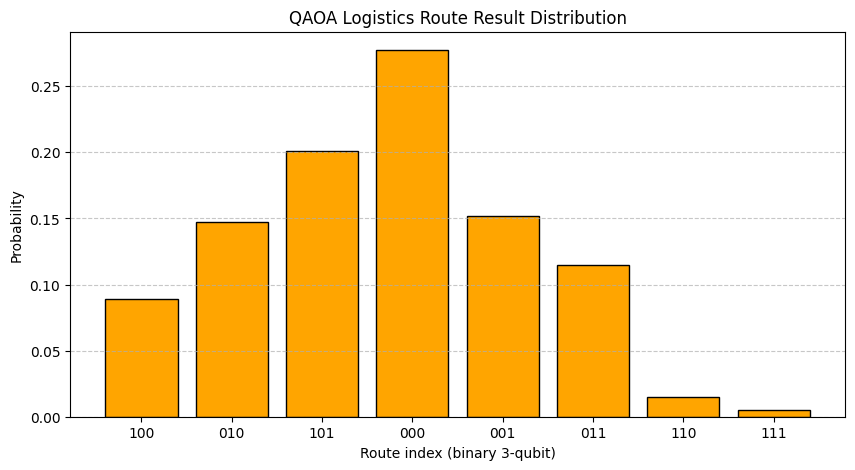

In [12]:
%matplotlib inline
import itertools
import numpy as np
import matplotlib.pyplot as plt

from qiskit.quantum_info import SparsePauliOp, Operator, Statevector
from qiskit.primitives import StatevectorSampler

from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)


# ==============================================================================
# STEP 2. 물류 배송 경로(Route) 및 비용(Cost) 정의
# ==============================================================================
# 창고 0번에서 출발하여 배송지 1, 2, 3을 한 번씩 방문하고 다시 0으로 돌아오는 경로를 설계합니다.
# 총 6개의 후보 경로(3! = 6)가 존재하며, 3큐비트(2^3 = 8개 상태)에 매핑합니다.
distance = np.array([
    [0, 4, 7, 6],
    [4, 0, 3, 8],
    [7, 3, 0, 5],
    [6, 8, 5, 0]
])

# 모든 배송 순서의 경우의 수를 구하고 시작/끝에 창고(0)를 추가
routes = [(0,) + p + (0,) for p in itertools.permutations([1, 2, 3])]

# 각 경로별 총 이동 거리(비용) 계산
costs = np.array([sum(distance[a, b] for a, b in zip(r, r[1:])) for r in routes], dtype=float)


# ==============================================================================
# STEP 3. 비용 함수 해밀턴산(Hamiltonian) 구성 (미사용 상태 벌점 부여)
# ==============================================================================
# 3큐비트는 총 8개의 상태(000~111)를 표현할 수 있지만, 유효한 경로는 6개뿐입니다.
# 유효하지 않은 나머지 2개 상태(인덱스 6, 7)에는 막대한 벌점(Penalty)을 주어 선택되지 않게 합니다.
diagonal = np.full(8, costs.max() + 20)
diagonal[:len(routes)] = costs  # 0~5번 인덱스에는 실제 경로 비용 대입

# 대각 행렬을 파울리 연산자 기반의 해밀턴산(H)으로 변환
H = SparsePauliOp.from_operator(Operator(np.diag(diagonal)))


# ==============================================================================
# STEP 4. QAOA 알고리즘 초기화 및 설정
# ==============================================================================
# - StatevectorSampler: 양자 회로의 측정 확률 분포를 샘플링
# - COBYLA: QAOA의 파라미터(감마, 베타)를 조정하는 고전 최적화기
# - reps=2: QAOA 회로 레이어 반복 횟수 (회로 깊이)
# - initial_point: 초기 감마/베타 각도 설정 [0.2, 0.4, 0.1, 0.3] (reps=2이므로 총 4개)
solver = QAOA(
    sampler=StatevectorSampler(default_shots=2048, seed=42),
    optimizer=COBYLA(maxiter=160),
    reps=2,
    initial_point=[0.2, 0.4, 0.1, 0.3]
)


# ==============================================================================
# STEP 5. QAOA 최적화 실행 (최적 파라미터 탐색)
# ==============================================================================
# 해밀턴산(H)을 입력하여 QAOA 최적화를 수행하고 최적의 측정 결과(Eigenstate)를 얻습니다.
print("=" * 60)
print("Running QAOA Logistics Optimization...")
print("=" * 60)

result = solver.compute_minimum_eigenvalue(H)


# ==============================================================================
# STEP 6. 결과 분석 및 정답 검증
# ==============================================================================
# 측정 결과에서 비트열 상태와 확률 분포(prob) 딕셔너리 생성
prob = {int(z, 2) if isinstance(z, str) else int(z): float(p) for z, p in result.eigenstate.items()}

# 유효한 경로(인덱스 0~5) 중 관측 확률이 0보다 큰 후보들 추출
candidates = [int(z) for z, p in prob.items() if p > 0 and int(z) < len(routes)]

# 후보 중 비용이 가장 최소가 되는 경로 선택
best = min(candidates, key=lambda z: costs[z])

print("\n" + "=" * 60)
print("QAOA Logistics Results & Verification")
print("=" * 60)
print("관측된 유효 후보 중 최소 비용 경로:", " → ".join(map(str, routes[best])))
print(f"선택 경로 비용      : {costs[best]} / 전수 탐색 최소 비용: {costs.min()}")
print(f"해당 경로 관측 확률 : {round(float(prob[best]), 4)}")
print(f"평균 비용(벌점 포함): {round(float(result.eigenvalue.real), 6)}")
print(f"최적해 관측 확률    : {round(sum(p for z, p in prob.items() if int(z) < 6 and costs[int(z)] == costs.min()), 4)}")

# 결과 검증
assert costs[best] == costs.min(), "QAOA가 최적의 배송 경로를 찾지 못했습니다!"
print("검증 통과: QAOA가 최적의 물류 경로를 정확히 찾아냈습니다.")


# ==============================================================================
# STEP 7. 결과 시각화 (확률 분포 바 차트)
# ============================================================--==============
# 3큐비트 상태 인덱스(000~111)별 관측 확률을 바 차트로 시각화합니다.
fig = plt.figure(figsize=(10, 5))

bitstring_labels = [format(int(z), '03b') for z in prob]
probabilities = list(prob.values())

plt.bar(bitstring_labels, probabilities, color='orange', edgecolor='black')
plt.xlabel("Route index (binary 3-qubit)")
plt.ylabel("Probability")
plt.title("QAOA Logistics Route Result Distribution")
plt.grid(axis='y', linestyle='--', alpha=0.7)

display(fig)
plt.show()